In [60]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare
import pandas as pd
import scikit_posthocs as sp
from datetime import timedelta

# Load files and get IoU scores

In [61]:
# load files
resnet_files = ['exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy', 'exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy', 'exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy']
dino_files = ['exports/unet/dino_np/dino_fdnzv5c2_e399_4_True_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy', 'exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_dice_0.0005_512_seed42_epoch100_pat10_per_image_iou_fold2.npy', 'exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy']
dino_256_files = ["exports/unet/06-21/13-50-26/dino_70queb8d_e399_4_False_adam_combined_0.0005_256_seed42_epoch100_pat20_per_image_iou_fold2.npy","exports/unet/06-21/13-50-26/dino_fdnzv5c2_e399_4_False_adam_iou_0.001_256_seed42_epoch100_pat20_per_image_iou_fold3.npy","exports/unet/06-21/13-50-26/dino_fdnzv5c2_e399_4_True_adam_dice_0.001_256_seed42_epoch100_pat20_per_image_iou_fold1.npy"]
baseline_files = ['exports/baseline/baseline_np/per_image_iou_fold1_baseline.npy', 'exports/baseline/baseline_np/per_image_iou_fold2_baseline.npy', 'exports/baseline/baseline_np/per_image_iou_fold3_baseline.npy']

def load_iou_scores(file_list):
    ious = []
    for file in file_list:
        data = np.load(file, allow_pickle=True)
        # Assuming shape (N, 2) with [image_id, iou]
        scores = [item[1] for item in data]
        ious.extend(scores)
    return ious

# Load IoUs for each model
resnet_ious = load_iou_scores(resnet_files)
dino_ious = load_iou_scores(dino_files)
dino_256_ious = load_iou_scores(dino_256_files)
baseline_ious = load_iou_scores(baseline_files)

In [62]:
def evaluate_model(name, file_paths):
    all_ious = []

    print(f"\n========== {name} ==========")
    for fold_index, path in enumerate(file_paths, start=1):
        data = np.load(path, allow_pickle=True)
        fold_ious = [float(iou) for _, iou in data]

        mean_fold_iou = np.mean(fold_ious)
        std_fold_iou = np.std(fold_ious)
        print(f"Fold {fold_index}: Mean IoU = {mean_fold_iou:.4f}, Std = {std_fold_iou:.4f}")

        all_ious.extend(fold_ious)

    overall_mean_iou = np.mean(all_ious)
    overall_std_iou = np.std(all_ious)
    print(f"\nOverall Mean IoU: {overall_mean_iou:.4f}")
    print(f"Overall Std IoU:  {overall_std_iou:.4f}")

# Evaluate each model
evaluate_model("ResNet50", resnet_files)
evaluate_model("DINO", dino_files)
evaluate_model("Baseline", baseline_files)


========== ResNet50 ==========
Fold 1: Mean IoU = 0.8050, Std = 0.0358
Fold 2: Mean IoU = 0.7830, Std = 0.0257
Fold 3: Mean IoU = 0.8241, Std = 0.0284

Overall Mean IoU: 0.8035
Overall Std IoU:  0.0346

========== DINO ==========
Fold 1: Mean IoU = 0.7888, Std = 0.0314
Fold 2: Mean IoU = 0.7963, Std = 0.0415
Fold 3: Mean IoU = 0.7796, Std = 0.0636

Overall Mean IoU: 0.7885
Overall Std IoU:  0.0475

========== Baseline ==========
Fold 1: Mean IoU = 0.6381, Std = 0.0455
Fold 2: Mean IoU = 0.6297, Std = 0.0414
Fold 3: Mean IoU = 0.6057, Std = 0.0552

Overall Mean IoU: 0.6249
Overall Std IoU:  0.0494


# Box-plots and 95\% Confidence Intervals

### Box-plots comparing models

/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_32728/293440441.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, labels=labels)


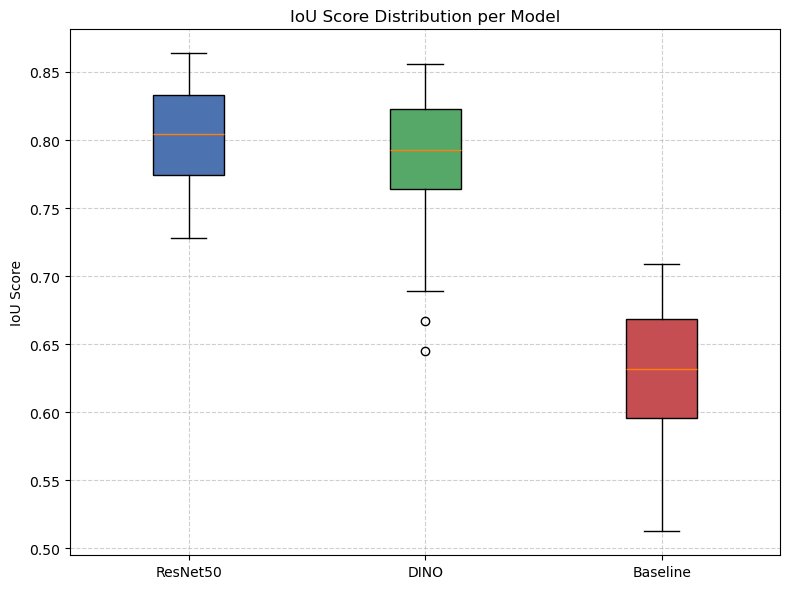


--- 95% Confidence Intervals ---
ResNet50: Mean IoU = 0.8035, 95% CI = [0.7928, 0.8143]
DINO: Mean IoU = 0.7885, 95% CI = [0.7737, 0.8032]
Baseline: Mean IoU = 0.6249, 95% CI = [0.6096, 0.6403]


In [75]:
# Create boxplot
data = [resnet_ious, dino_ious, baseline_ious]
labels = ['ResNet50', 'DINO', 'Baseline']
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red

plt.figure(figsize=(8, 6))
box = plt.boxplot(data, patch_artist=True, labels=labels)

# Apply colors to each box
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')

plt.ylabel('IoU Score')
plt.title('IoU Score Distribution per Model')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n--- 95% Confidence Intervals ---")
for label, group in zip(labels, data):
    mean = np.mean(group)
    std = np.std(group, ddof=1)
    n = len(group)
    ci_half_width = 1.96 * (std / np.sqrt(n))
    ci_low = mean - ci_half_width
    ci_high = mean + ci_half_width
    print(f"{label}: Mean IoU = {mean:.4f}, 95% CI = [{ci_low:.4f}, {ci_high:.4f}]")


### Box-plots comparing image size: 256 vs 512

/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_32728/3658200913.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, labels=labels)


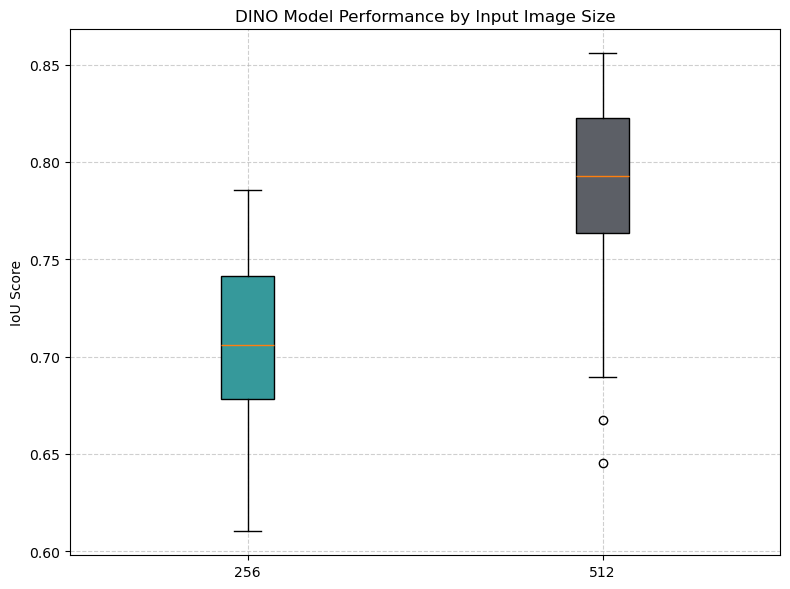


--- 95% Confidence Intervals ---
256: Mean IoU = 0.7095, 95% CI = [0.6961, 0.7230]
512: Mean IoU = 0.7885, 95% CI = [0.7737, 0.8032]


In [74]:
# Create boxplot
data = [dino_256_ious,dino_ious]
labels = ['256', '512']
colors = ["#36999B",'#5C5F66']

plt.figure(figsize=(8, 6))
box = plt.boxplot(data, patch_artist=True, labels=labels)

# Apply colors to each box
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')

plt.ylabel('IoU Score')
plt.title('DINO Model Performance by Input Image Size')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Calculate and print confidence intervals
print("\n--- 95% Confidence Intervals ---")
for label, group in zip(labels, data):
    mean = np.mean(group)
    std = np.std(group, ddof=1)
    n = len(group)
    ci_half_width = 1.96 * (std / np.sqrt(n))
    ci_low = mean - ci_half_width
    ci_high = mean + ci_half_width
    print(f"{label}: Mean IoU = {mean:.4f}, 95% CI = [{ci_low:.4f}, {ci_high:.4f}]")


# Time vs IoU score

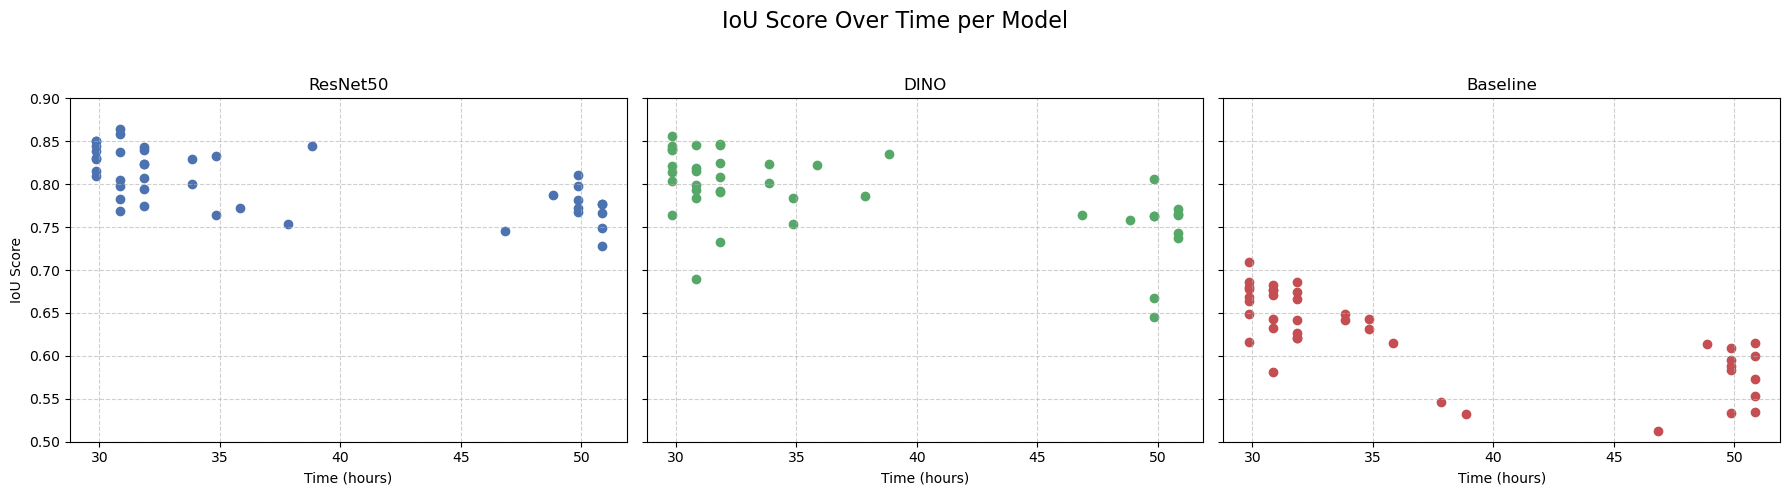

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta

def parse_hms_time(t_str):
    hours = int(t_str.split('h')[0])
    minutes = int(t_str.split('h')[1].split('m')[0])
    seconds = int(t_str.split('m')[1].split('s')[0])
    return timedelta(hours=hours, minutes=minutes, seconds=seconds)

def extract_time_iou(file_list):
    times = []
    ious = []
    for file in file_list:
        data = np.load(file, allow_pickle=True)
        for image_id, iou in data:
            try:
                hms_str = image_id.split('_')[1]
                td = parse_hms_time(hms_str)
                hours = td.total_seconds() / 3600
                times.append(hours)
                ious.append(iou)
            except Exception as e:
                print(f"Error parsing {image_id}: {e}")
    return times, ious

# Define your model files first: resnet_files, dino_files, baseline_files

model_configs = [
    ("ResNet50", resnet_files, '#4C72B0'),
    ("DINO", dino_files, '#55A868'),
    ("Baseline", baseline_files, '#C44E52')
]

# Determine global y-axis limits
all_ious = []
for _, file_list, _ in model_configs:
    _, ious = extract_time_iou(file_list)
    all_ious.extend(ious)

min_iou = 0.5
max_iou = 0.9  # force top limit

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (model_name, file_list, color) in zip(axes, model_configs):
    times, ious = extract_time_iou(file_list)
    sorted_pairs = sorted(zip(times, ious))
    sorted_times, sorted_ious = zip(*sorted_pairs)

    ax.scatter(sorted_times, sorted_ious, color=color, alpha=1.0)
    ax.set_title(model_name)
    ax.set_xlabel('Time (hours)')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_ylim(min_iou, max_iou)

axes[0].set_ylabel('IoU Score')

plt.suptitle('IoU Score Over Time per Model', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for the suptitle
plt.show()

# Shapiro-Wilk test

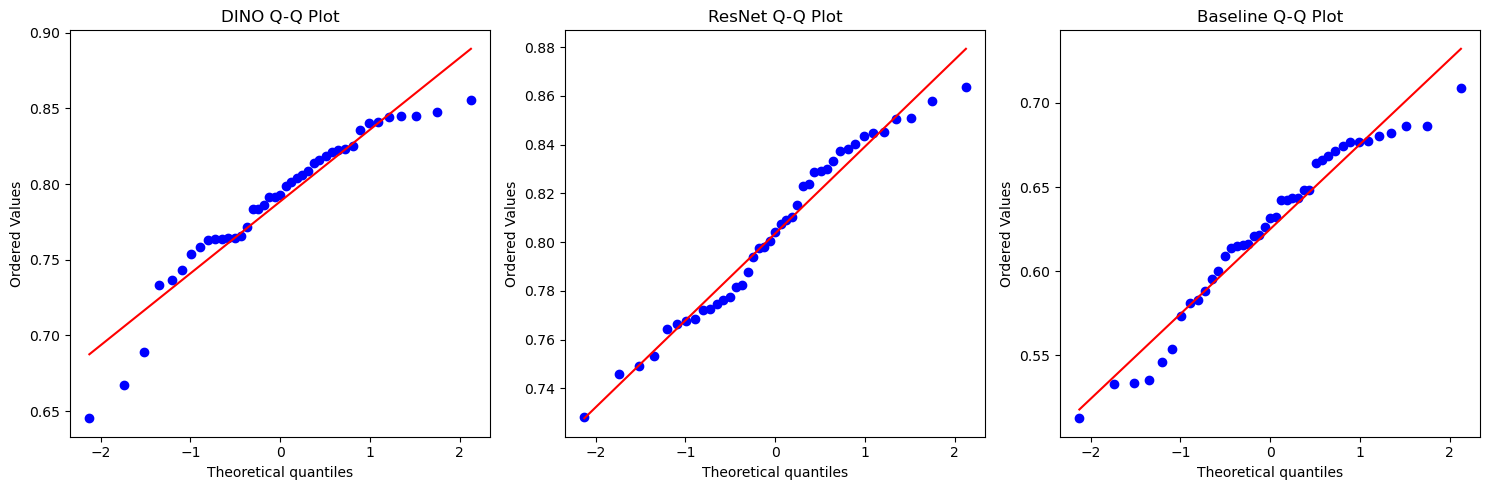

Shapiro-Wilk Test Results:
DINO:     W=0.9193, p=0.0065
ResNet50: W=0.9660, p=0.2544
Baseline: W=0.9492, p=0.0658


In [66]:

# Run Shapiro-Wilk test for normality
shapiro_dino = stats.shapiro(dino_ious)
shapiro_resnet = stats.shapiro(resnet_ious)
shapiro_baseline = stats.shapiro(baseline_ious)

# Create Q-Q plots to visually assess normality
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
stats.probplot(dino_ious, dist="norm", plot=axes[0])
axes[0].set_title("DINO Q-Q Plot")

stats.probplot(resnet_ious, dist="norm", plot=axes[1])
axes[1].set_title("ResNet Q-Q Plot")

stats.probplot(baseline_ious, dist="norm", plot=axes[2])
axes[2].set_title("Baseline Q-Q Plot")

plt.tight_layout()
plt.show()

# Print Shapiro-Wilk test results
print("Shapiro-Wilk Test Results:")
print(f"DINO:     W={shapiro_dino.statistic:.4f}, p={shapiro_dino.pvalue:.4f}")
print(f"ResNet50: W={shapiro_resnet.statistic:.4f}, p={shapiro_resnet.pvalue:.4f}")
print(f"Baseline: W={shapiro_baseline.statistic:.4f}, p={shapiro_baseline.pvalue:.4f}")

# Friedman test

In [67]:
# Run Friedman test
statistic, p_value = friedmanchisquare(resnet_ious, dino_ious, baseline_ious)

# Print results
print(f"Friedman test statistic: {statistic:.4f}, p-value: {p_value:.4f}")

# Interpret
alpha = 0.05
if p_value < alpha:
    print("→ Significant differences between models (reject H0)")
else:
    print("→ No significant differences between models (fail to reject H0)")


Friedman test statistic: 63.4146, p-value: 0.0000
→ Significant differences between models (reject H0)


# Nemenyi post-hoc test

Nemenyi post hoc p-values:

              ResNet50          DINO      Baseline
ResNet50  1.000000e+00  6.970987e-02  3.208545e-14
DINO      6.970987e-02  1.000000e+00  1.006846e-07
Baseline  3.208545e-14  1.006846e-07  1.000000e+00


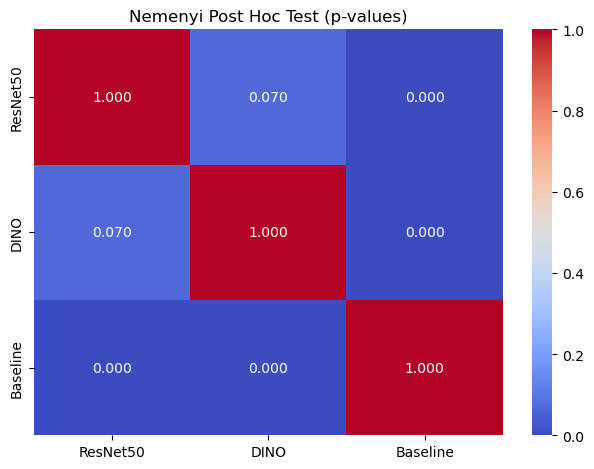

In [68]:
# Create DataFrame
df = pd.DataFrame({
    'ResNet50': resnet_ious,
    'DINO': dino_ious,
    'Baseline': baseline_ious
})

# Run Nemenyi post hoc test
nemenyi = sp.posthoc_nemenyi_friedman(df)

# Show results
print("Nemenyi post hoc p-values:\n")
print(nemenyi)

# Optional: heatmap
sns.heatmap(nemenyi, annot=True, fmt=".3f", cmap="coolwarm", xticklabels=df.columns, yticklabels=df.columns)
plt.title("Nemenyi Post Hoc Test (p-values)")
plt.tight_layout()
plt.show()